## Problem and data description

### Decision problem

A fleet of identical vehicles must leave one depot, serve every customer exactly once, and return to the depot. Each customer has a non-negative demand, and the total demand assigned to a vehicle cannot exceed its capacity. The objective is to minimize total travel distance.

This is representative of last-mile delivery, collection, maintenance, and bike-rebalancing operations. A good solution lowers distance, vehicle use, fuel consumption, and operating time while satisfying all service and capacity requirements.

In [1]:
import json
import math
import os
import platform
import random
import time
from datetime import datetime, timezone
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp
import psutil
import requests
from IPython.display import FileLink, display
from scipy.spatial.distance import cdist

# Use one baseline seed so the primary synthetic experiment is reproducible.
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
pd.set_option("display.max_columns", None)

# Record the execution environment because hardware and solver versions affect runtime comparisons.
print("Python experiment environment loaded successfully.")
runtime_environment = pd.DataFrame(
    {
        "Component": [
            "Python", "Operating system", "Machine", "Processor",
            "Logical CPU cores", "Memory (GB)", "PuLP", "HiGHS",
            "Folium", "Timing boundary",
        ],
        "Value": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            platform.processor() or os.environ.get("PROCESSOR_IDENTIFIER", "Not reported"),
            psutil.cpu_count(logical=True),
            round(psutil.virtual_memory().total / (1024 ** 3), 2),
            pulp.__version__,
            getattr(__import__("highspy"), "__version__", "Available through PuLP"),
            folium.__version__,
            "Includes model/population construction and optimization, but excludes data generation and plotting",
        ],
    }
)
display(runtime_environment)


Python experiment environment loaded successfully.


,Component,Value
0,Python,3.13.2
1,Operating system,Windows-11-10.0.26300-SP0
2,Machine,AMD64
3,Processor,"Intel64 Family 6 Model 183 Stepping 1, Genuine..."
4,Logical CPU cores,28
5,Memory (GB),31.75
6,PuLP,4.0.0
7,HiGHS,Available through PuLP
8,Folium,0.20.0
9,Timing boundary,Includes model/population construction and opt...


### Controlled synthetic benchmark

The controlled benchmark places a depot at the centre of a 100 by 100 service region and generates customers with demands between 1 and 10 units. One coordinate unit is treated as one abstract distance unit. Euclidean distance represents travel in an unobstructed or approximately grid-like region. This abstraction is useful for controlled algorithm comparison but does not reproduce one-way streets, traffic, or road curvature.

Separate seeded random streams generate coordinates and demands, so the experiments are reproducible and smaller instances are prefixes of larger instances generated with the same seed. Synthetic data is used here to control problem size and isolate scalability effects. A later section uses a saved real Citi Bike snapshot and road-distance results to provide real-world validation.

,Metric,Value
0,Customers,10
1,Vehicles,3
2,Capacity per vehicle,25
3,Total demand,49
4,Total fleet capacity,75
5,Seed,42


Complete controlled synthetic dataset


,Node_ID,Node_Type,X_coordinate,Y_coordinate,Demand
Node,,,,,
Depot,0,Depot,50.000,50.000,0
Customer_1,1,Customer,77.396,43.888,6
Customer_2,2,Customer,85.860,69.737,7
Customer_3,3,Customer,9.418,97.562,5
Customer_4,4,Customer,76.114,78.606,1
Customer_5,5,Customer,12.811,45.039,6
Customer_6,6,Customer,37.080,92.676,1
Customer_7,7,Customer,64.387,82.276,3
Customer_8,8,Customer,44.341,22.724,9


Complete Euclidean distance matrix (abstract distance units)


,Depot,Customer_1,Customer_2,Customer_3,Customer_4,Customer_5,Customer_6,Customer_7,Customer_8,Customer_9,Customer_10
From / To,,,,,,,,,,,
Depot,0.00,28.07,40.93,62.52,38.73,37.52,44.59,35.34,27.86,43.96,35.31
Customer_1,28.07,0.00,27.20,86.61,34.74,64.59,63.29,40.53,39.25,43.45,20.01
Customer_2,40.93,27.20,0.00,81.35,13.18,77.11,53.90,24.87,62.72,70.27,7.26
Customer_3,62.52,86.61,81.35,0.00,69.34,52.63,28.09,57.05,82.59,102.15,81.01
Customer_4,38.73,34.74,13.18,69.34,0.00,71.65,41.49,12.29,64.28,75.12,16.81
Customer_5,37.52,64.59,77.11,52.63,71.65,0.00,53.46,63.61,38.63,57.56,72.26
Customer_6,44.59,63.29,53.90,28.09,41.49,53.46,0.00,29.22,70.33,88.23,54.39
Customer_7,35.34,40.53,24.87,57.05,12.29,63.61,29.22,0.00,62.84,76.42,26.51
Customer_8,27.86,39.25,62.72,82.59,64.28,38.63,70.33,62.84,0.00,19.76,55.78


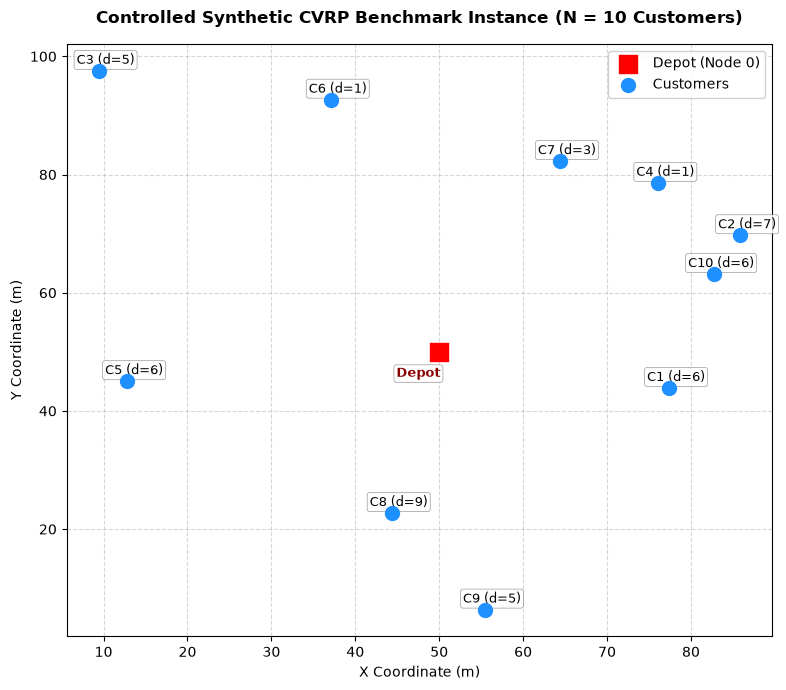

In [ ]:
# Validate every instance before optimization so invalid inputs cannot produce misleading results.
def validate_instance_data(instance):
    required = {
        "num_nodes", "num_customers", "num_vehicles",
        "vehicle_capacity", "dist_matrix", "demands",
    }
    missing = sorted(required.difference(instance))
    if missing:
        raise ValueError(f"Missing instance fields: {missing}")

    n = int(instance["num_customers"])
    node_count = int(instance["num_nodes"])
    vehicle_count = int(instance["num_vehicles"])
    capacity = float(instance["vehicle_capacity"])
    demands = np.asarray(instance["demands"], dtype=float)
    distances = np.asarray(instance["dist_matrix"], dtype=float)

    if n < 2 or node_count != n + 1:
        raise ValueError("An instance must contain a depot and at least two customers.")
    if vehicle_count <= 0 or capacity <= 0:
        raise ValueError("Vehicle count and capacity must be positive.")
    if demands.shape != (node_count,) or distances.shape != (node_count, node_count):
        raise ValueError("Demand vector or distance-matrix dimensions do not match the node count.")
    if not np.all(np.isfinite(demands)) or np.any(demands < 0) or demands[0] != 0:
        raise ValueError("Demands must be finite and non-negative, with zero demand at the depot.")
    if np.any(demands[1:] > capacity):
        raise ValueError("At least one customer demand exceeds vehicle capacity.")
    if demands.sum() > vehicle_count * capacity:
        raise ValueError("Total demand exceeds total fleet capacity.")
    if not np.all(np.isfinite(distances)) or np.any(distances < 0):
        raise ValueError("Distances must be finite and non-negative.")
    if not np.allclose(np.diag(distances), 0):
        raise ValueError("The distance-matrix diagonal must be zero.")
    return True


# Generate a controlled CVRP instance with independent seeded streams for coordinates and demands.
def generate_vrp_instance(
    num_customers=15,
    grid_size=100,
    max_demand=10,
    vehicle_capacity=30,
    num_vehicles=4,
    seed=42,
):
    coordinate_rng = np.random.default_rng(seed)
    demand_rng = np.random.default_rng(seed + 1)

    # Fix the depot at the centre and sample customers throughout the service region.
    depot_coords = np.array([[grid_size / 2, grid_size / 2]], dtype=float)
    customer_coords = coordinate_rng.uniform(0, grid_size, size=(num_customers, 2))
    coords = np.vstack([depot_coords, customer_coords])
    dist_matrix = cdist(coords, coords, metric="euclidean")
    demands = np.r_[0, demand_rng.integers(1, max_demand + 1, size=num_customers)]

    data = {
        "num_nodes": num_customers + 1,
        "num_customers": num_customers,
        "num_vehicles": num_vehicles,
        "vehicle_capacity": vehicle_capacity,
        "coords": coords,
        "dist_matrix": dist_matrix,
        "demands": demands,
        "distance_unit": "abstract distance units",
        "seed": seed,
    }
    validate_instance_data(data)
    return data

def plot_vrp_instance(data):
    """
    Plots the spatial distribution of the depot and customer nodes
    along with their individual demand annotations.
    """
    coords = data["coords"]
    demands = data["demands"]
    
    plt.figure(figsize=(8, 7))
    
    # Plot Depot (Node 0)
    plt.scatter(coords[0, 0], coords[0, 1], c='red', marker='s', s=150, label='Depot (Node 0)', zorder=5)
    
    # Plot Customers (Nodes 1 to N)
    plt.scatter(coords[1:, 0], coords[1:, 1], c='dodgerblue', marker='o', s=100, label='Customers', zorder=4)
    
    # Annotate Node IDs and Demands
    for i in range(len(coords)):
        if i == 0:
            label = "Depot"
            xytext = (-15, -18)
            fontweight = 'bold'
            color = 'darkred'
        else:
            label = f"C{i} (d={int(demands[i])})"
            xytext = (5, 5)
            fontweight = 'normal'
            color = 'black'
            
        plt.annotate(
            label,
            (coords[i, 0], coords[i, 1]),
            textcoords="offset points",
            xytext=xytext,
            ha='center',
            fontsize=9,
            fontweight=fontweight,
            color=color,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", lw=0.5, alpha=0.8)
        )
        
    plt.title(f"Controlled Synthetic CVRP Benchmark Instance (N = {data['num_customers']} Customers)", fontsize=12, fontweight='bold', pad=15)
    plt.xlabel("X Coordinate (m)", fontsize=10)
    plt.ylabel("Y Coordinate (m)", fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper right', framealpha=0.9)
    plt.tight_layout()
    
    
    plt.show()

data = generate_vrp_instance(
    num_customers=10,
    vehicle_capacity=25,
    num_vehicles=3,
    seed=SEED,
)

instance_summary = pd.DataFrame(
    {
        "Metric": ["Customers", "Vehicles", "Capacity per vehicle", "Total demand", "Total fleet capacity", "Seed"],
        "Value": [
            data["num_customers"],
            data["num_vehicles"],
            data["vehicle_capacity"],
            int(data["demands"].sum()),
            data["num_vehicles"] * data["vehicle_capacity"],
            data["seed"],
        ],
    }
)
display(instance_summary)

# Present the generated inputs explicitly so the experiment can be audited and reproduced.
node_labels = ["Depot"] + [f"Customer_{customer}" for customer in range(1, data["num_customers"] + 1)]
synthetic_dataset = pd.DataFrame(
    {
        "Node_ID": range(data["num_nodes"]),
        "Node_Type": ["Depot"] + ["Customer"] * data["num_customers"],
        "X_coordinate": data["coords"][:, 0],
        "Y_coordinate": data["coords"][:, 1],
        "Demand": data["demands"].astype(int),
    },
    index=node_labels,
)
synthetic_dataset.index.name = "Node"
print("Complete controlled synthetic dataset")
display(synthetic_dataset.round({"X_coordinate": 3, "Y_coordinate": 3}))

distance_matrix_display = pd.DataFrame(
    data["dist_matrix"],
    index=node_labels,
    columns=node_labels,
).round(2)
distance_matrix_display.index.name = "From / To"
print(f"Complete Euclidean distance matrix ({data['distance_unit']})")
display(distance_matrix_display)
plot_vrp_instance(data)

## Method 1 Integer Linear Programming

ILP is appropriate because CVRP decisions are discrete and its operational constraints can be written explicitly. When the solver reports `Optimal`, the returned objective is globally optimal for the model. The weakness is computational growth: CVRP is NP-hard, and the number of binary arc variables grows approximately with (O(mn^2)). A time-limited run may return a valid incumbent without proving optimality; therefore solver status, best bound, and MIP gap are reported rather than assuming every ILP result is optimal.


In [3]:
# Solve the capacitated VRP as a mixed-integer linear program using HiGHS.
def solve_vrp_exact_ilp(data, time_limit_sec=60):
    validate_instance_data(data)
    n = data["num_customers"]
    nodes = list(range(n + 1))
    customers = list(range(1, n + 1))
    vehicles = list(range(data["num_vehicles"]))
    costs = data["dist_matrix"]
    demands = [float(value) for value in data["demands"]]
    capacity = float(data["vehicle_capacity"])

    start_time = time.perf_counter()
    problem = pulp.LpProblem("Capacitated_VRP", pulp.LpMinimize)
    # x[i,j,k] equals 1 when vehicle k travels directly from node i to node j.
    x = problem.add_variable_dicts(
        "x",
        ((i, j, k) for i in nodes for j in nodes for k in vehicles if i != j),
        cat="Binary",
    )
    # u variables support the load-based MTZ subtour-elimination constraints.
    u = problem.add_variable_dicts(
        "u",
        ((i, k) for i in customers for k in vehicles),
        lowBound=0,
        upBound=capacity,
        cat="Continuous",
    )

    # Minimize total distance across all selected vehicle arcs.
    problem += pulp.lpSum(
        costs[i][j] * x[i, j, k]
        for i in nodes for j in nodes if i != j for k in vehicles
    )

    # Every customer must have exactly one incoming visit across the fleet.
    for customer in customers:
        problem += pulp.lpSum(
            x[i, customer, k]
            for i in nodes if i != customer for k in vehicles
        ) == 1

    # Enforce vehicle flow conservation, depot usage, capacity, and subtour elimination.
    for k in vehicles:
        for node in nodes:
            problem += pulp.lpSum(x[i, node, k] for i in nodes if i != node) == pulp.lpSum(
                x[node, j, k] for j in nodes if j != node
            )
        problem += pulp.lpSum(x[0, j, k] for j in customers) <= 1
        problem += pulp.lpSum(
            demands[i] * x[i, j, k]
            for i in customers for j in nodes if i != j
        ) <= capacity

        for i in customers:
            for j in customers:
                if i != j:
                    problem += u[i, k] - u[j, k] + capacity * x[i, j, k] <= capacity - demands[j]

    # A time limit keeps scalability experiments bounded while retaining the best feasible incumbent.
    solver = pulp.HiGHS(timeLimit=time_limit_sec, msg=False)
    if not solver.available():
        raise RuntimeError('HiGHS is unavailable. Install it with: %pip install "pulp>=4,<5" highspy')
    stats = problem.solve(solver)
    execution_time = time.perf_counter() - start_time
    # Read native HiGHS diagnostics because PuLP's generic status omits the bound and MIP gap.
    solver_info = problem.solverModel.getInfo() if hasattr(problem, "solverModel") else None

    def finite_solver_value(attribute):
        value = getattr(solver_info, attribute, None) if solver_info is not None else None
        return float(value) if value is not None and np.isfinite(value) else None

    best_bound = finite_solver_value("mip_dual_bound")
    mip_gap = finite_solver_value("mip_gap")
    explored_nodes = finite_solver_value("mip_node_count")

    if not stats.has_solution:
        return {
            "status": stats.status_str,
            "objective": float("inf"),
            "routes": [],
            "runtime": execution_time,
            "is_optimal": False,
            "best_bound": best_bound,
            "mip_gap": mip_gap,
            "explored_nodes": explored_nodes,
        }

    # Reconstruct ordered depot-to-depot routes from selected binary arcs.
    routes = []
    for k in vehicles:
        route = [0]
        current = 0
        seen = set()
        while True:
            next_node = next(
                (
                    j for j in nodes
                    if j != current
                    and pulp.value(x[current, j, k]) is not None
                    and pulp.value(x[current, j, k]) > 0.5
                ),
                None,
            )
            if next_node is None or next_node == 0:
                if len(route) > 1:
                    route.append(0)
                break
            if next_node in seen:
                raise RuntimeError("Unexpected repeated customer while reconstructing an ILP route.")
            seen.add(next_node)
            route.append(next_node)
            current = next_node
        if len(route) > 2:
            routes.append(route)

    return {
        "status": stats.status_str,
        "objective": float(pulp.value(problem.objective)),
        "routes": routes,
        "runtime": execution_time,
        "is_optimal": stats.status == pulp.LpSolveStatus.Optimal,
        "best_bound": best_bound,
        "mip_gap": mip_gap,
        "explored_nodes": explored_nodes,
    }


exact_results = solve_vrp_exact_ilp(data, time_limit_sec=60)
exact_results


{'status': 'Optimal',
 'objective': 370.559013389067,
 'routes': [[0, 5, 3, 6, 0], [0, 1, 10, 2, 4, 7, 0], [0, 9, 8, 0]],
 'runtime': 6.8345898000006855,
 'is_optimal': True,
 'best_bound': 370.55901338906705,
 'mip_gap': 0.0,
 'explored_nodes': 3033.0}

## Method 2 Genetic Algorithm

The GA represents a candidate as a permutation of customer identifiers. A deterministic greedy decoder scans the permutation and starts a new route whenever adding the next customer would exceed vehicle capacity. Tournament selection favours fitter individuals, ordered crossover preserves permutation validity, and swap mutation introduces diversity. A large penalty discourages chromosomes requiring more than the available vehicles.

The GA was selected because it can quickly search a large combinatorial space without enumerating every route. It does not prove optimality and its result varies with the random seed, so repeated runs and convergence history are evaluated.

In [4]:
# Represent each GA individual as a permutation of customer identifiers.
class GeneticAlgorithmVRP:
    def __init__(
        self,
        data,
        pop_size=100,
        generations=200,
        crossover_rate=0.8,
        mutation_rate=0.2,
        seed=42,
    ):
        validate_instance_data(data)
        if pop_size < 2 or generations < 1:
            raise ValueError("GA population size must be at least 2 and generations must be positive.")
        if not 0 <= crossover_rate <= 1 or not 0 <= mutation_rate <= 1:
            raise ValueError("GA crossover and mutation rates must be between 0 and 1.")
        self.data = data
        self.pop_size = pop_size
        self.generations = generations
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.num_customers = data["num_customers"]
        self.customers = list(range(1, self.num_customers + 1))
        self.rng = random.Random(seed)

    # Greedily split a permutation into capacity-feasible depot-to-depot routes.
    def decode_chromosome(self, chromosome):
        routes = []
        current_route = [0]
        current_load = 0
        for customer in chromosome:
            demand = int(self.data["demands"][customer])
            if current_load + demand <= self.data["vehicle_capacity"]:
                current_route.append(customer)
                current_load += demand
            else:
                current_route.append(0)
                routes.append(current_route)
                current_route = [0, customer]
                current_load = demand
        current_route.append(0)
        routes.append(current_route)
        return routes

    def calculate_total_distance(self, routes):
        return sum(
            float(self.data["dist_matrix"][a][b])
            for route in routes for a, b in zip(route, route[1:])
        )

    # Penalize solutions that require more routes than the available fleet.
    def fitness(self, chromosome):
        routes = self.decode_chromosome(chromosome)
        distance = self.calculate_total_distance(routes)
        excess_routes = max(0, len(routes) - self.data["num_vehicles"])
        penalty = excess_routes * 1_000_000
        return 1.0 / (distance + penalty + 1e-9)

    # Ordered crossover preserves a valid customer permutation without duplicates.
    def ordered_crossover(self, parent1, parent2):
        if self.rng.random() > self.crossover_rate:
            return parent1.copy(), parent2.copy()
        size = len(parent1)
        a, b = sorted(self.rng.sample(range(size), 2))

        def ox(first, second):
            child = [-1] * size
            child[a:b + 1] = first[a:b + 1]
            remaining = [item for item in second if item not in child]
            cursor = 0
            for position in range(size):
                if child[position] == -1:
                    child[position] = remaining[cursor]
                    cursor += 1
            return child

        return ox(parent1, parent2), ox(parent2, parent1)

    # Swap mutation introduces diversity while keeping the chromosome valid.
    def mutate_swap(self, chromosome):
        if self.rng.random() < self.mutation_rate:
            i, j = self.rng.sample(range(len(chromosome)), 2)
            chromosome[i], chromosome[j] = chromosome[j], chromosome[i]
        return chromosome

    # Evolve the population and retain the best feasible solution found so far.
    def solve(self):
        start_time = time.perf_counter()
        population = [self.rng.sample(self.customers, len(self.customers)) for _ in range(self.pop_size)]
        best_chromosome = None
        best_distance = float("inf")
        history = []

        for _ in range(self.generations):
            fitness_scores = [self.fitness(individual) for individual in population]
            for individual in population:
                routes = self.decode_chromosome(individual)
                distance = self.calculate_total_distance(routes)
                if len(routes) <= self.data["num_vehicles"] and distance < best_distance:
                    best_distance = distance
                    best_chromosome = individual.copy()
            history.append(best_distance)

            # Binary tournament selection favours fitter individuals without removing diversity completely.
            selected = []
            for _ in range(self.pop_size):
                first, second = self.rng.sample(range(self.pop_size), 2)
                winner = population[first] if fitness_scores[first] > fitness_scores[second] else population[second]
                selected.append(winner.copy())

            next_population = []
            for index in range(0, self.pop_size, 2):
                parent1 = selected[index]
                parent2 = selected[(index + 1) % self.pop_size]
                child1, child2 = self.ordered_crossover(parent1, parent2)
                next_population.extend([self.mutate_swap(child1), self.mutate_swap(child2)])
            population = next_population[: self.pop_size]

        runtime = time.perf_counter() - start_time
        if best_chromosome is None:
            return {
                "status": "No feasible solution found",
                "objective": float("inf"),
                "routes": [],
                "runtime": runtime,
                "convergence_history": history,
                "is_optimal": False,
            }
        return {
            "status": "Feasible heuristic",
            "objective": best_distance,
            "routes": self.decode_chromosome(best_chromosome),
            "runtime": runtime,
            "convergence_history": history,
            "is_optimal": False,
        }


ga_solver = GeneticAlgorithmVRP(
    data,
    pop_size=100,
    generations=250,
    crossover_rate=0.85,
    mutation_rate=0.15,
    seed=SEED,
)
ga_results = ga_solver.solve()
ga_results


{'status': 'Feasible heuristic',
 'objective': 382.05014572147445,
 'routes': [[0, 3, 6, 7, 4, 2, 10, 0], [0, 1, 9, 8, 0], [0, 5, 0]],
 'runtime': 0.2584814000001643,
 'convergence_history': [480.88831273051943,
  456.5284859373888,
  456.5284859373888,
  456.5284859373888,
  441.7979307573666,
  413.2339960550214,
  413.2339960550214,
  413.2339960550214,
  413.2339960550214,
  413.2339960550214,
  413.2339960550214,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  383.8798566852661,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.05014572147445,
  382.050145721474

## Feasibility validation and baseline comparison

A low objective value is meaningful only if all constraints are satisfied. The validator below independently checks depot returns, customer coverage, duplicates, node indices, route count, and capacity. This guards against comparing an infeasible heuristic route with an ILP solution.


In [5]:
# Independently validate routes rather than trusting either solver's reported objective.
def validate_solution(data, routes):
    errors = []
    customers = []
    route_loads = []
    route_distances = []

    if len(routes) > data["num_vehicles"]:
        errors.append("The number of routes exceeds the vehicle limit.")

    for route_number, route in enumerate(routes, start=1):
        if len(route) < 3 or route[0] != 0 or route[-1] != 0:
            errors.append(f"Route {route_number} does not start and end at the depot.")
        inner = route[1:-1]
        if any(not isinstance(node, (int, np.integer)) or node < 1 or node > data["num_customers"] for node in inner):
            errors.append(f"Route {route_number} contains an invalid customer index.")
        load = int(sum(data["demands"][node] for node in inner))
        if load > data["vehicle_capacity"]:
            errors.append(f"Route {route_number} exceeds capacity: {load} > {data['vehicle_capacity']}.")
        route_loads.append(load)
        route_distances.append(sum(float(data["dist_matrix"][a][b]) for a, b in zip(route, route[1:])))
        customers.extend(inner)

    expected = list(range(1, data["num_customers"] + 1))
    if sorted(customers) != expected:
        errors.append("Customers are missing, duplicated, or visited more than once.")

    return {
        "feasible": not errors,
        "errors": errors,
        "route_loads": route_loads,
        "route_distances": route_distances,
        "total_distance": float(sum(route_distances)),
    }


# Require both feasibility and agreement between the reported and reconstructed objectives.
def assert_result_consistency(data, method, result):
    validation = validate_solution(data, result["routes"])
    if not validation["feasible"]:
        raise ValueError(f"{method} returned an infeasible solution: {validation['errors']}")
    if not np.isclose(validation["total_distance"], result["objective"], rtol=1e-7, atol=1e-7):
        raise ValueError(
            f"{method} objective {result['objective']} does not match reconstructed route distance "
            f"{validation['total_distance']}."
        )
    return validation


# Convert nested route lists into an auditable vehicle-level comparison table.
def build_route_table(data, results_by_method, node_names=None):
    rows = []
    for method, result in results_by_method.items():
        validation = assert_result_consistency(data, method, result)
        for route_number, (route, load, distance) in enumerate(
            zip(result["routes"], validation["route_loads"], validation["route_distances"]),
            start=1,
        ):
            route_labels = [node_names[node] if node_names else str(node) for node in route]
            rows.append(
                {
                    "Method": method,
                    "Vehicle": route_number,
                    "Route": " -> ".join(route_labels),
                    "Load": load,
                    "Capacity": data["vehicle_capacity"],
                    "Capacity_Utilization_pct": 100 * load / data["vehicle_capacity"],
                    "Route_Distance": distance,
                    "Total_Method_Distance": result["objective"],
                    "Runtime_s": result["runtime"],
                    "Feasible": validation["feasible"],
                }
            )
    return pd.DataFrame(rows)


# Apply the same independent checks to the exact and heuristic baseline solutions.
baseline_rows = []
for method, result in (("ILP", exact_results), ("GA", ga_results)):
    validation = assert_result_consistency(data, method, result)
    baseline_rows.append(
        {
            "Method": method,
            "Status": result["status"],
            "Distance": result["objective"],
            "Runtime_s": result["runtime"],
            "Routes_used": len(result["routes"]),
            "Route_loads": validation["route_loads"],
            "Feasible": validation["feasible"],
            "Proven_optimal": result.get("is_optimal", False),
        }
    )

baseline_comparison = pd.DataFrame(baseline_rows)
baseline_gap = 100 * (ga_results["objective"] - exact_results["objective"]) / exact_results["objective"]
display(baseline_comparison)
baseline_route_table = build_route_table(data, {"ILP": exact_results, "GA": ga_results})
display(baseline_route_table.round(4))
print(f"GA distance difference from the ILP incumbent: {baseline_gap:.2f}%")


,Method,Status,Distance,Runtime_s,Routes_used,Route_loads,Feasible,Proven_optimal
0,ILP,Optimal,370.559013,6.834590,3,"[12, 23, 14]",True,True
1,GA,Feasible heuristic,382.050146,0.258481,3,"[23, 20, 6]",True,False


,Method,Vehicle,Route,Load,Capacity,Capacity_Utilization_pct,Route_Distance,Total_Method_Distance,Runtime_s,Feasible
0,ILP,1,0 -> 5 -> 3 -> 6 -> 0,12,25,48.0,162.8309,370.5590,6.8346,True
1,ILP,2,0 -> 1 -> 10 -> 2 -> 4 -> 7 -> 0,23,25,92.0,116.1477,370.5590,6.8346,True
2,ILP,3,0 -> 9 -> 8 -> 0,14,25,56.0,91.5804,370.5590,6.8346,True
3,GA,1,0 -> 3 -> 6 -> 7 -> 4 -> 2 -> 10 -> 0,23,25,92.0,187.8723,382.0501,0.2585,True
4,GA,2,0 -> 1 -> 9 -> 8 -> 0,20,25,80.0,119.1415,382.0501,0.2585,True
5,GA,3,0 -> 5 -> 0,6,25,24.0,75.0363,382.0501,0.2585,True


GA distance difference from the ILP incumbent: 3.10%


## Evaluation 


In [6]:
# Compare scalability across problem sizes, independent instance seeds, and repeated GA runs.
def run_benchmark_experiments(
    customer_scales=(8, 12, 15, 18),
    instance_seeds=(100, 101),
    ga_repetitions=5,
    ilp_time_limit=10,
):
    instance_rows = []
    ga_run_rows = []
    for n in customer_scales:
        # Multiple instance seeds reduce the risk of drawing conclusions from one favourable layout.
        for instance_seed in instance_seeds:
            print(f"Benchmarking N={n} customers, instance seed={instance_seed}")
            bench_data = generate_vrp_instance(
                num_customers=n,
                vehicle_capacity=30,
                num_vehicles=4,
                seed=instance_seed,
            )
            # Verify the ILP incumbent even when the solver reaches its time limit.
            ilp_result = solve_vrp_exact_ilp(bench_data, time_limit_sec=ilp_time_limit)
            ilp_validation = assert_result_consistency(bench_data, f"ILP N={n} seed={instance_seed}", ilp_result)

            ga_runs = []
            # Repeat the stochastic GA with recorded seeds to quantify variability.
            for repetition in range(ga_repetitions):
                ga_seed = instance_seed * 100 + repetition
                ga = GeneticAlgorithmVRP(
                    bench_data,
                    pop_size=100,
                    generations=250,
                    crossover_rate=0.85,
                    mutation_rate=0.15,
                    seed=ga_seed,
                )
                result = ga.solve()
                validation = assert_result_consistency(
                    bench_data, f"GA N={n} instance={instance_seed} run={repetition + 1}", result
                )
                best_generation = int(np.argmin(result["convergence_history"])) + 1
                ga_runs.append(result)
                ga_run_rows.append(
                    {
                        "N_Customers": n,
                        "Instance_Seed": instance_seed,
                        "GA_Run": repetition + 1,
                        "GA_Seed": ga_seed,
                        "Objective": result["objective"],
                        "Runtime_s": result["runtime"],
                        "Routes_Used": len(result["routes"]),
                        "Feasible": validation["feasible"],
                        "Objective_Verified": np.isclose(validation["total_distance"], result["objective"]),
                        "Best_Found_Generation": best_generation,
                    }
                )

            ga_costs = np.array([result["objective"] for result in ga_runs], dtype=float)
            ga_times = np.array([result["runtime"] for result in ga_runs], dtype=float)
            best_ga = ga_runs[int(np.argmin(ga_costs))]
            proven_gap = (
                100 * (best_ga["objective"] - ilp_result["objective"]) / ilp_result["objective"]
                if ilp_result.get("is_optimal") and ilp_result["objective"] > 0
                else np.nan
            )
            instance_rows.append(
                {
                    "N_Customers": n,
                    "Instance_Seed": instance_seed,
                    "Total_Demand": int(bench_data["demands"].sum()),
                    "ILP_Status": ilp_result["status"],
                    "ILP_Proven_Optimal": ilp_result.get("is_optimal", False),
                    "ILP_Feasible": ilp_validation["feasible"],
                    "ILP_Objective_Verified": np.isclose(ilp_validation["total_distance"], ilp_result["objective"]),
                    "ILP_Cost": ilp_result["objective"],
                    "ILP_Best_Bound": ilp_result.get("best_bound"),
                    "ILP_MIP_Gap": ilp_result.get("mip_gap"),
                    "ILP_Explored_Nodes": ilp_result.get("explored_nodes"),
                    "ILP_Runtime_s": ilp_result["runtime"],
                    "GA_Best_Cost": float(ga_costs.min()),
                    "GA_Mean_Cost": float(ga_costs.mean()),
                    "GA_Cost_Std": float(ga_costs.std(ddof=1)),
                    "GA_Mean_Runtime_s": float(ga_times.mean()),
                    "GA_Runtime_Std_s": float(ga_times.std(ddof=1)),
                    "GA_Feasible_Runs": len(ga_runs),
                    "GA_Repetitions": ga_repetitions,
                    "Proven_Optimality_Gap_pct": proven_gap,
                }
            )

    instance_results = pd.DataFrame(instance_rows)
    ga_run_results = pd.DataFrame(ga_run_rows)
    # Aggregate instance-level outcomes only after retaining all detailed run records.
    summary_rows = []
    for n, group in instance_results.groupby("N_Customers", sort=True):
        ga_group = ga_run_results[ga_run_results["N_Customers"] == n]
        valid_gaps = group["Proven_Optimality_Gap_pct"].dropna()
        summary_rows.append(
            {
                "N_Customers": n,
                "Instances": len(group),
                "Total_Demand": group["Total_Demand"].mean(),
                "ILP_Status": f"{int(group['ILP_Proven_Optimal'].sum())}/{len(group)} optimal",
                "ILP_Proven_Optimal": bool(group["ILP_Proven_Optimal"].all()),
                "ILP_Feasible": bool(group["ILP_Feasible"].all()),
                "ILP_Cost": group["ILP_Cost"].mean(),
                "ILP_Best_Bound": group["ILP_Best_Bound"].mean(),
                "ILP_MIP_Gap": group["ILP_MIP_Gap"].mean(),
                "ILP_Runtime_s": group["ILP_Runtime_s"].mean(),
                "GA_Best_Cost": group["GA_Best_Cost"].mean(),
                "GA_Mean_Cost": ga_group["Objective"].mean(),
                "GA_Cost_Std": ga_group["Objective"].std(ddof=1),
                "GA_Mean_Runtime_s": ga_group["Runtime_s"].mean(),
                "GA_Runtime_Std_s": ga_group["Runtime_s"].std(ddof=1),
                "GA_Feasible_Runs": int(ga_group["Feasible"].sum()),
                "GA_Repetitions": len(ga_group),
                "Proven_Optimality_Gap_pct": valid_gaps.mean() if not valid_gaps.empty else np.nan,
            }
        )
    return pd.DataFrame(summary_rows), instance_results, ga_run_results


df_comparison, df_instance_results, df_ga_runs = run_benchmark_experiments()
print("Per-instance benchmark results")
display(df_instance_results.round(4))
print("Individual GA runs")
display(df_ga_runs.round(4))
print("Scalability summary across instance seeds")
display(df_comparison.round(4))


Benchmarking N=8 customers, instance seed=100
Benchmarking N=8 customers, instance seed=101
Benchmarking N=12 customers, instance seed=100
Benchmarking N=12 customers, instance seed=101
Benchmarking N=15 customers, instance seed=100
Benchmarking N=15 customers, instance seed=101
Benchmarking N=18 customers, instance seed=100
Benchmarking N=18 customers, instance seed=101
Per-instance benchmark results


,N_Customers,Instance_Seed,Total_Demand,ILP_Status,ILP_Proven_Optimal,ILP_Feasible,ILP_Objective_Verified,ILP_Cost,ILP_Best_Bound,ILP_MIP_Gap,ILP_Explored_Nodes,ILP_Runtime_s,GA_Best_Cost,GA_Mean_Cost,GA_Cost_Std,GA_Mean_Runtime_s,GA_Runtime_Std_s,GA_Feasible_Runs,GA_Repetitions,Proven_Optimality_Gap_pct
0,8,100,45,Optimal,True,True,True,313.4812,313.4806,0.0000,530.0,3.1625,313.4812,313.5315,0.0688,0.2167,0.0017,5,5,0.0000
1,8,101,37,Optimal,True,True,True,319.9905,319.9820,0.0000,1394.0,3.6889,323.2878,324.1785,1.9916,0.2180,0.0030,5,5,1.0304
2,12,100,69,TimeLimit,False,True,True,385.8852,298.3116,0.2269,1720.0,10.0405,385.8852,392.9859,9.7254,0.2917,0.0104,5,5,NaN
3,12,101,57,TimeLimit,False,True,True,392.1052,322.4186,0.1777,2320.0,10.0375,392.1052,393.0117,1.8623,0.2726,0.0026,5,5,NaN
4,15,100,88,TimeLimit,False,True,True,455.0537,289.3749,0.3641,743.0,10.0589,438.6501,445.0963,10.0272,0.3420,0.0098,5,5,NaN
5,15,101,79,TimeLimit,False,True,True,484.9923,366.6409,0.2440,632.0,10.0569,472.0554,485.0808,13.3069,0.3319,0.0034,5,5,NaN
6,18,100,103,TimeLimit,False,True,True,569.0181,390.0308,0.3146,165.0,10.0835,570.4680,585.8779,15.1399,0.3906,0.0046,5,5,NaN
7,18,101,102,TimeLimit,False,True,True,575.7312,360.3594,0.3741,392.0,10.0846,549.2472,564.0254,11.6591,0.3923,0.0032,5,5,NaN


Individual GA runs


,N_Customers,Instance_Seed,GA_Run,GA_Seed,Objective,Runtime_s,Routes_Used,Feasible,Objective_Verified,Best_Found_Generation
0,8,100,1,10000,313.4812,0.2182,2,True,True,13
1,8,100,2,10001,313.4812,0.2162,2,True,True,19
2,8,100,3,10002,313.4812,0.2182,2,True,True,9
3,8,100,4,10003,313.6069,0.2167,2,True,True,31
4,8,100,5,10004,313.6069,0.2142,2,True,True,12
5,8,101,1,10100,323.2878,0.2182,2,True,True,13
6,8,101,2,10101,323.2878,0.2174,2,True,True,6
7,8,101,3,10102,323.2878,0.2184,2,True,True,17
8,8,101,4,10103,323.2878,0.2139,2,True,True,4
9,8,101,5,10104,327.7411,0.2222,2,True,True,10


Scalability summary across instance seeds


,N_Customers,Instances,Total_Demand,ILP_Status,ILP_Proven_Optimal,ILP_Feasible,ILP_Cost,ILP_Best_Bound,ILP_MIP_Gap,ILP_Runtime_s,GA_Best_Cost,GA_Mean_Cost,GA_Cost_Std,GA_Mean_Runtime_s,GA_Runtime_Std_s,GA_Feasible_Runs,GA_Repetitions,Proven_Optimality_Gap_pct
0,8,2,41.0,2/2 optimal,True,True,316.7359,316.7313,0.0000,3.4257,318.3845,318.8550,5.7666,0.2174,0.0024,10,10,0.5152
1,12,2,63.0,0/2 optimal,False,True,388.9952,310.3651,0.2023,10.0390,388.9952,392.9988,6.6014,0.2822,0.0124,10,10,NaN
2,15,2,83.5,0/2 optimal,False,True,470.0230,328.0079,0.3041,10.0579,455.3528,465.0885,23.8220,0.3370,0.0087,10,10,NaN
3,18,2,102.5,0/2 optimal,False,True,572.3746,375.1951,0.3443,10.0840,559.8576,574.9516,17.1737,0.3915,0.0038,10,10,NaN


## Visual comparison

The figures show route structure, stochastic convergence, runtime growth, solution quality, and the proven optimality gap where one is available. Missing gap values mean that the ILP time limit expired before optimality was proved; they do not mean the gap was zero.



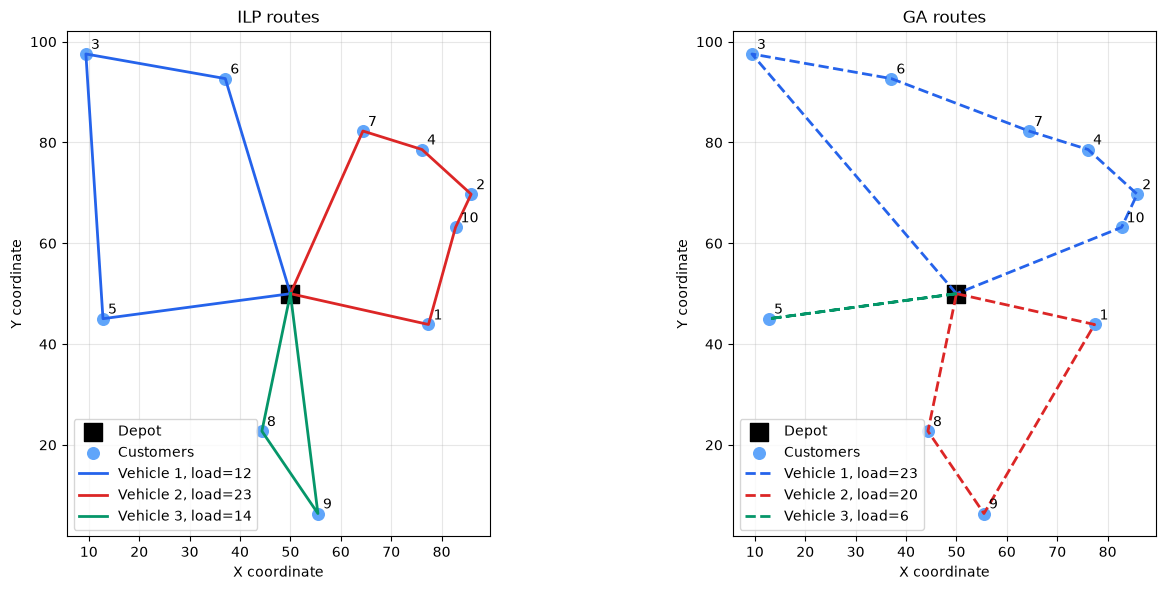

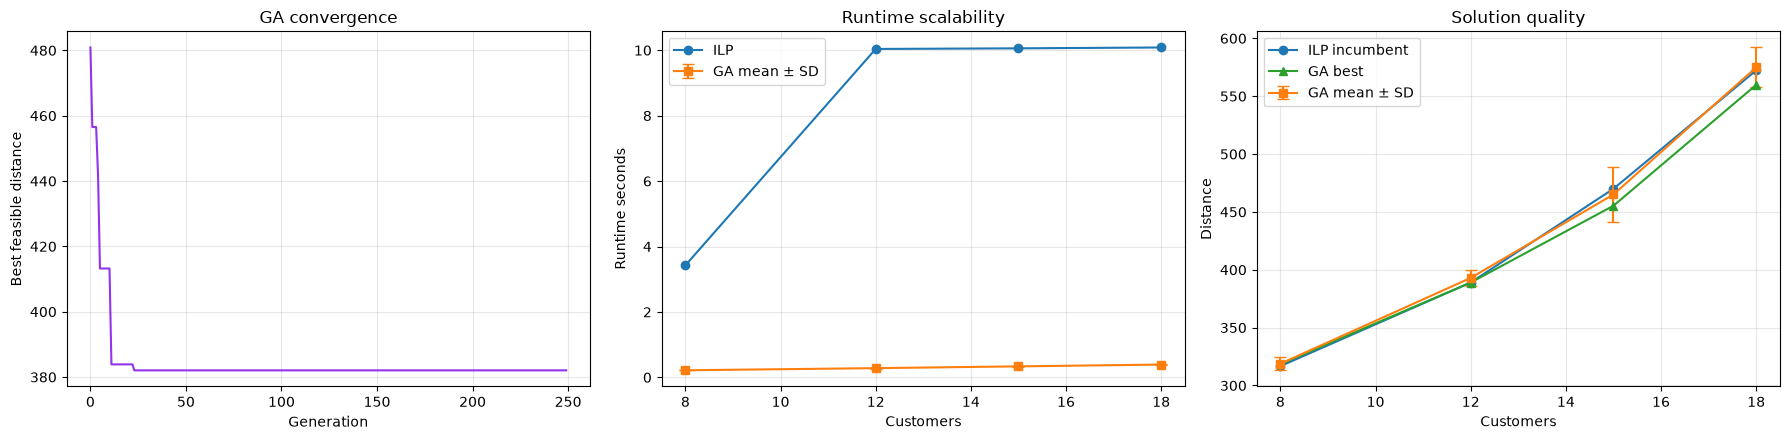

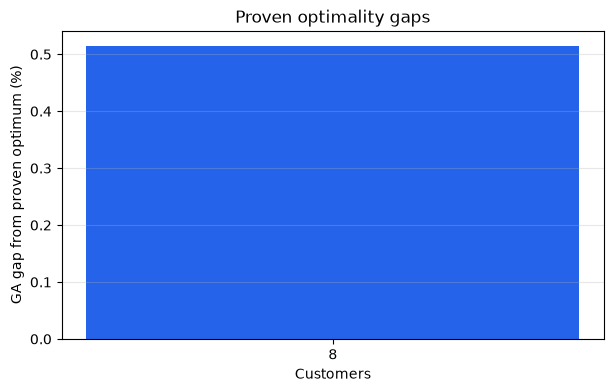

In [15]:
# Plot both route sets on identical axes so their structures can be compared fairly.
def plot_routes_comparison(data, ilp_routes, ga_routes):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    colors = ["#2563eb", "#dc2626", "#059669", "#9333ea", "#ea580c"]
    for axis, title, routes, linestyle in (
        (axes[0], "ILP routes", ilp_routes, "-"),
        (axes[1], "GA routes", ga_routes, "--"),
    ):
        coords = data["coords"]
        axis.scatter(coords[0, 0], coords[0, 1], c="black", s=150, marker="s", label="Depot")
        axis.scatter(coords[1:, 0], coords[1:, 1], c="#60a5fa", s=70, label="Customers")
        for node, (x_value, y_value) in enumerate(coords[1:], start=1):
            axis.annotate(str(node), (x_value + 1, y_value + 1))
        for route_index, route in enumerate(routes):
            route_coords = coords[route]
            load = int(sum(data["demands"][node] for node in route[1:-1]))
            axis.plot(
                route_coords[:, 0],
                route_coords[:, 1],
                color=colors[route_index % len(colors)],
                linewidth=2,
                linestyle=linestyle,
                label=f"Vehicle {route_index + 1}, load={load}",
            )
        axis.set_title(title)
        axis.set_xlabel("X coordinate")
        axis.set_ylabel("Y coordinate")
        axis.set_aspect("equal", adjustable="box")
        axis.grid(alpha=0.3)
        axis.legend()
    plt.tight_layout()
    plt.show()


# Guard against running this visualization cell with stale or incomplete kernel state.
required_objects = {"data", "exact_results", "ga_results", "run_benchmark_experiments"}
missing_objects = sorted(required_objects.difference(globals()))
if missing_objects:
    raise RuntimeError(
        "Required earlier results are missing: " + ", ".join(missing_objects)
        + ". Restart the kernel and run all cells from the top."
    )

required_benchmark_columns = {
    "N_Customers", "ILP_Runtime_s", "GA_Mean_Runtime_s",
    "GA_Runtime_Std_s", "ILP_Cost", "GA_Mean_Cost",
    "GA_Cost_Std", "GA_Best_Cost", "Proven_Optimality_Gap_pct",
}
if ("df_comparison" not in globals()
        or not required_benchmark_columns.issubset(df_comparison.columns)):
    print("A missing or older benchmark table was detected; rebuilding it now.")
    df_comparison, df_instance_results, df_ga_runs = run_benchmark_experiments()
    if not required_benchmark_columns.issubset(df_comparison.columns):
        raise RuntimeError(
            "The kernel still contains the older benchmark function. "
            "Restart the kernel and run all cells from the top."
        )
    display(df_comparison.round(4))

plot_routes_comparison(data, exact_results["routes"], ga_results["routes"])

# Show GA convergence, runtime growth, and solution quality as complementary evidence.
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(ga_results["convergence_history"], color="#9333ea")
axes[0].set(title="GA convergence", xlabel="Generation", ylabel="Best feasible distance")
axes[0].grid(alpha=0.3)

axes[1].plot(df_comparison["N_Customers"], df_comparison["ILP_Runtime_s"], marker="o", label="ILP")
axes[1].errorbar(
    df_comparison["N_Customers"],
    df_comparison["GA_Mean_Runtime_s"],
    yerr=df_comparison["GA_Runtime_Std_s"],
    marker="s",
    capsize=4,
    label="GA mean ± SD",
)
axes[1].set(title="Runtime scalability", xlabel="Customers", ylabel="Runtime seconds")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].plot(df_comparison["N_Customers"], df_comparison["ILP_Cost"], marker="o", label="ILP incumbent")
axes[2].errorbar(
    df_comparison["N_Customers"],
    df_comparison["GA_Mean_Cost"],
    yerr=df_comparison["GA_Cost_Std"],
    marker="s",
    capsize=4,
    label="GA mean ± SD",
)
axes[2].plot(df_comparison["N_Customers"], df_comparison["GA_Best_Cost"], marker="^", label="GA best")
axes[2].set(title="Solution quality", xlabel="Customers", ylabel="Distance")
axes[2].grid(alpha=0.3)
axes[2].legend()
plt.tight_layout()
plt.show()

# Plot gaps only where the ILP solution was actually proven optimal.
gap_rows = df_comparison.dropna(subset=["Proven_Optimality_Gap_pct"])
if not gap_rows.empty:
    plt.figure(figsize=(7, 4))
    plt.bar(gap_rows["N_Customers"].astype(str), gap_rows["Proven_Optimality_Gap_pct"], color="#2563eb")
    plt.xlabel("Customers")
    plt.ylabel("GA gap from proven optimum (%)")
    plt.title("Proven optimality gaps")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
else:
    print("No benchmark instance was proven optimal within the configured ILP time limit.")


In [8]:
# Summarize the baseline trade-off using only independently validated results.
best_ga_row = baseline_comparison.loc[baseline_comparison["Method"] == "GA"].iloc[0]
ilp_row = baseline_comparison.loc[baseline_comparison["Method"] == "ILP"].iloc[0]
print("Baseline interpretation")
print(f"- Both solutions feasible: {bool(ilp_row['Feasible'] and best_ga_row['Feasible'])}")
print(f"- ILP distance: {ilp_row['Distance']:.2f}")
print(f"- GA distance: {best_ga_row['Distance']:.2f}")
print(f"- GA distance difference from ILP incumbent: {baseline_gap:.2f}%")
print(f"- ILP runtime: {ilp_row['Runtime_s']:.4f} seconds")
print(f"- GA runtime: {best_ga_row['Runtime_s']:.4f} seconds")
print("- A GA gap is called an optimality gap only when ILP_Proven_Optimal is True.")

Baseline interpretation
- Both solutions feasible: True
- ILP distance: 370.56
- GA distance: 382.05
- GA distance difference from ILP incumbent: 3.10%
- ILP runtime: 6.8346 seconds
- GA runtime: 0.2585 seconds
- A GA gap is called an optimality gap only when ILP_Proven_Optimal is True.


## Real-world validation using a Citi Bike snapshot

The saved snapshot contains station names, coordinates, available-bike counts, and reporting timestamps from Citi Bike's public GBFS feed. The scenario is a hypothetical pickup operation: vehicles start at an assumed Times Square depot, collect available bicycles from eight nearby active stations, and return to the depot. This is not a claim about Citi Bike's actual rebalancing policy.

The optimization distance matrix is requested from the public OSRM Table API (`https://router.project-osrm.org/table/v1/driving/`) using the depot and selected station coordinates. OSRM distances represent routed driving distance in kilometres and can be asymmetric because of the road network. If the public service is unavailable, the notebook uses a clearly labelled deterministic fallback equal to great-circle distance multiplied by a 1.25 road-circuity factor. OSRM map data is based on OpenStreetMap contributors. The exact matrix and the source actually used are displayed below.

In [12]:
# Public routing endpoints used for the real-world road-distance matrix and map geometry.
OSRM_TABLE_URL = "https://router.project-osrm.org/table/v1/driving"
OSRM_ROUTE_URL = "https://router.project-osrm.org/route/v1/driving"
OSRM_ATTRIBUTION = "OSRM routing service using OpenStreetMap contributor data"


# Provide a deterministic offline approximation if the public OSRM service is unavailable.
def great_circle_distance_matrix(latlon):
    latitudes = np.radians(latlon[:, 0])
    longitudes = np.radians(latlon[:, 1])
    lat_1, lat_2 = np.meshgrid(latitudes, latitudes, indexing="ij")
    lon_1, lon_2 = np.meshgrid(longitudes, longitudes, indexing="ij")
    haversine_a = np.sin((lat_2 - lat_1) / 2) ** 2 + np.cos(lat_1) * np.cos(lat_2) * np.sin((lon_2 - lon_1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(haversine_a, 0, 1)))


# Request an asymmetric driving-distance matrix; clearly label any fallback that is used.
def obtain_road_distance_matrix(latlon):
    coordinates = ";".join(f"{lon:.7f},{lat:.7f}" for lat, lon in latlon)
    try:
        response = requests.get(
            f"{OSRM_TABLE_URL}/{coordinates}",
            params={"annotations": "distance"},
            timeout=30,
        )
        response.raise_for_status()
        payload = response.json()
        distances = np.asarray(payload.get("distances"), dtype=float) / 1000.0
        if payload.get("code") != "Ok" or distances.shape != (len(latlon), len(latlon)) or not np.all(np.isfinite(distances)):
            raise RuntimeError("OSRM returned an incomplete distance matrix.")
        np.fill_diagonal(distances, 0.0)
        return distances, "OSRM Table API driving distance (km)"
    except (requests.RequestException, RuntimeError, TypeError, ValueError) as error:
        fallback = great_circle_distance_matrix(latlon) * 1.25
        np.fill_diagonal(fallback, 0.0)
        return fallback, f"Great-circle distance x 1.25 fallback because OSRM was unavailable: {type(error).__name__}"


LIVE_DIRECTORY = Path("live_data")
snapshots = sorted(LIVE_DIRECTORY.glob("citibike_*.json"))

if not snapshots:
    print("The Citi Bike snapshot is missing. Keep the synthetic experiment as the reproducible evaluation.")
    live_data_available = False
else:
    live_data_available = True
    snapshot_path = snapshots[-1]
    snapshot = json.loads(snapshot_path.read_text(encoding="utf-8"))
    # Join static station coordinates with the corresponding operational status records.
    station_info = pd.DataFrame(snapshot["information"]["data"]["stations"])
    station_status = pd.DataFrame(snapshot["status"]["data"]["stations"])
    station_info["station_id"] = station_info["station_id"].astype(str)
    station_status["station_id"] = station_status["station_id"].astype(str)
    stations = station_info[["station_id", "name", "lat", "lon"]].merge(
        station_status, on="station_id", validate="one_to_one"
    )
    for column in ("lat", "lon", "num_bikes_available", "last_reported"):
        stations[column] = pd.to_numeric(stations[column], errors="raise")

    depot = np.array([40.7580, -73.9855])
    # Restrict the scenario to nearby, active stations with manageable pickup demand.
    eligible_stations = stations[
        stations["lat"].between(40.73, 40.79)
        & stations["lon"].between(-74.01, -73.96)
        & stations["num_bikes_available"].between(1, 10)
        & (stations["is_installed"] == 1)
        & (stations["is_renting"] == 1)
        & (stations["is_returning"] == 1)
    ].copy()
    eligible_station_count = len(eligible_stations)
    eligible_stations["proximity"] = (
        (eligible_stations["lat"] - depot[0]) ** 2
        + ((eligible_stations["lon"] - depot[1]) * np.cos(np.radians(depot[0]))) ** 2
    )
    selected = eligible_stations.sort_values(["proximity", "station_id"]).head(8).reset_index(drop=True)
    live_latlon = np.vstack([depot, selected[["lat", "lon"]].to_numpy(dtype=float)])
    live_demands = np.r_[0, selected["num_bikes_available"].to_numpy(dtype=int)]
    live_names = ["Assumed depot: Times Square"] + selected["name"].tolist()
    selected["last_reported_utc"] = pd.to_datetime(selected["last_reported"], unit="s", utc=True)
    # Build the exact distance matrix that will be passed to both optimization methods.
    live_distance_matrix, live_distance_source = obtain_road_distance_matrix(live_latlon)
    live_data = {
        "num_nodes": len(live_latlon),
        "num_customers": len(live_latlon) - 1,
        "num_vehicles": 2,
        "vehicle_capacity": 20,
        "coords": live_latlon,
        "dist_matrix": live_distance_matrix,
        "demands": live_demands,
        "distance_unit": "km",
        "seed": SEED,
    }
    validate_instance_data(live_data)
    feed_updated_at_utc = pd.to_datetime(snapshot["status"]["last_updated"], unit="s", utc=True).isoformat()

    # Expose provenance, filtering decisions, attribution, and fallback policy in the notebook output.
    source_metadata = pd.DataFrame(
        {
            "Metric": [
                "Data source",
                "Snapshot file",
                "Snapshot retrieved at (UTC)",
                "Feed updated at (UTC)",
                "Stations in information feed",
                "Stations in status feed",
                "Matched stations",
                "Eligible stations before nearest-eight selection",
                "Stations selected for optimization",
                "Assumed depot",
                "Selection rule",
                "Optimization vehicles and capacity",
                "Distance source used in this execution",
                "OSRM endpoint",
                "Road-data attribution",
                "Offline fallback policy",
            ],
            "Value": [
                snapshot.get("source", "Not recorded"),
                str(snapshot_path),
                snapshot.get("retrieved_at_utc", "Not recorded"),
                feed_updated_at_utc,
                len(station_info),
                len(station_status),
                len(stations),
                eligible_station_count,
                len(selected),
                "Times Square (40.7580, -73.9855)",
                "Active stations within the Manhattan bounding box, with 1-10 available bikes; select the eight nearest to the assumed depot",
                "2 vehicles, 20 bicycles per vehicle",
                live_distance_source,
                OSRM_TABLE_URL,
                OSRM_ATTRIBUTION,
                "Great-circle distance multiplied by 1.25 and explicitly labelled as a fallback",
            ],
        }
    )
    live_data_dictionary = pd.DataFrame(
        {
            "Field": ["station_id", "name", "lat", "lon", "num_bikes_available", "last_reported", "is_installed", "is_renting", "is_returning"],
            "Meaning": [
                "Unique Citi Bike station identifier",
                "Station name",
                "Latitude in decimal degrees",
                "Longitude in decimal degrees",
                "Bicycles available for the hypothetical pickup demand",
                "Station status reporting time; displayed below as a UTC date-time",
                "Whether the station is installed",
                "Whether the station is currently allowing rentals",
                "Whether the station is currently accepting returns",
            ],
        }
    )

    print("Citi Bike source and filtering metadata")
    display(source_metadata)
    print("Citi Bike field descriptions")
    display(live_data_dictionary)
    print("Selected stations used in the optimization instance")
    display(selected[["station_id", "name", "num_bikes_available", "lat", "lon", "last_reported_utc"]])
    live_distance_table = pd.DataFrame(live_distance_matrix, index=live_names, columns=live_names)
    live_distance_table.index.name = "From / To"
    print(f"Road-distance matrix used for optimization: {live_distance_source}")
    display(live_distance_table.round(3))


Citi Bike source and filtering metadata


,Metric,Value
0,Data source,https://gbfs.citibikenyc.com/gbfs/gbfs.json
1,Snapshot file,live_data\citibike_20261014T084839Z.json
2,Snapshot retrieved at (UTC),2026-10-14T08:48:34.125890+00:00
3,Feed updated at (UTC),2026-10-14T08:48:26+00:00
4,Stations in information feed,2519
5,Stations in status feed,2519
6,Matched stations,2519
7,Eligible stations before nearest-eight selection,77
8,Stations selected for optimization,8
9,Assumed depot,"Times Square (40.7580, -73.9855)"


Citi Bike field descriptions


,Field,Meaning
0,station_id,Unique Citi Bike station identifier
1,name,Station name
2,lat,Latitude in decimal degrees
3,lon,Longitude in decimal degrees
4,num_bikes_available,Bicycles available for the hypothetical pickup...
5,last_reported,Station status reporting time; displayed below...
6,is_installed,Whether the station is installed
7,is_renting,Whether the station is currently allowing rentals
8,is_returning,Whether the station is currently accepting ret...


Selected stations used in the optimization instance


,station_id,name,num_bikes_available,lat,lon,last_reported_utc
0,64f0f28c-bedc-42d5-b107-ecdd48fc30cd,Broadway & W 48 St,2,40.760177,-73.984868,2026-10-14 08:47:59+00:00
1,904930bd-2671-4695-9c1a-8a894b041129,6 Ave & W 45 St,1,40.756951,-73.982631,2026-10-14 08:46:27+00:00
2,2c366f4b-8319-41bf-ab8e-2fba3a952feb,W 42 St & 6 Ave,2,40.754920,-73.984550,2026-10-14 08:48:08+00:00
3,66dc82ef-0aca-11e7-82f6-3863bb44ef7c,W 43 St & 6 Ave,1,40.755273,-73.983169,2026-10-14 08:47:27+00:00
4,053312f2-e77e-4674-b28b-ad357fbcb4ee,8 Ave & W 49 St,4,40.761712,-73.986551,2026-10-14 08:46:56+00:00
5,2004153375425087884,W 51 St & 7 Ave,1,40.761670,-73.982560,2026-10-14 08:46:54+00:00
6,66dc1e55-0aca-11e7-82f6-3863bb44ef7c,W 49 St & 8 Ave,1,40.762272,-73.987882,2026-10-14 08:46:38+00:00
7,66de8a86-0aca-11e7-82f6-3863bb44ef7c,W 52 St & 6 Ave,2,40.761330,-73.979820,2026-10-14 08:46:47+00:00


Road-distance matrix used for optimization: OSRM Table API driving distance (km)


,Assumed depot: Times Square,Broadway & W 48 St,6 Ave & W 45 St,W 42 St & 6 Ave,W 43 St & 6 Ave,8 Ave & W 49 St,W 51 St & 7 Ave,W 49 St & 8 Ave,W 52 St & 6 Ave
From / To,,,,,,,,,
Assumed depot: Times Square,0.000,0.723,1.631,0.487,1.721,0.603,1.558,0.728,1.354
Broadway & W 48 St,0.302,0.000,1.225,0.790,1.316,0.587,0.834,0.712,1.333
6 Ave & W 45 St,0.566,0.970,0.000,1.053,0.872,0.850,0.709,0.975,1.208
W 42 St & 6 Ave,1.185,1.200,0.964,0.000,1.517,1.079,1.672,1.204,1.831
W 43 St & 6 Ave,0.792,1.197,0.227,0.643,0.000,1.076,0.935,1.202,1.434
8 Ave & W 49 St,0.743,1.147,1.663,1.230,1.754,0.000,0.954,0.676,0.752
W 51 St & 7 Ave,0.492,0.897,1.413,0.980,1.504,0.461,0.000,0.586,0.893
W 49 St & 8 Ave,1.006,0.703,1.927,1.493,2.018,0.583,1.855,0.000,1.334
W 52 St & 6 Ave,1.013,1.809,1.232,1.501,1.323,1.000,0.986,1.125,0.000


In [13]:
# Retrieve road-following geometry for visualization; optimization uses the Table API matrix above.
def osrm_route_geometry(points):
    coordinates = ";".join(f"{lon:.7f},{lat:.7f}" for lat, lon in points)
    response = requests.get(
        f"{OSRM_ROUTE_URL}/{coordinates}",
        params={"overview": "full", "geometries": "geojson", "continue_straight": "false"},
        timeout=20,
    )
    response.raise_for_status()
    payload = response.json()
    if payload.get("code") != "Ok" or not payload.get("routes"):
        raise RuntimeError("OSRM did not return a route.")
    return [[lat, lon] for lon, lat in payload["routes"][0]["geometry"]["coordinates"]]


# Create an interactive OpenStreetMap view after checking station coverage and route capacity.
def make_folium_route_map(method, method_result, capacity=20):
    routes = method_result["routes"]
    visited = sorted(node for route in routes for node in route[1:-1])
    if visited != list(range(1, len(live_latlon))):
        raise ValueError(f"{method} live route does not visit every station exactly once.")
    route_map = folium.Map(location=live_latlon[0].tolist(), zoom_start=14, tiles="OpenStreetMap", control_scale=True)
    for node, point in enumerate(live_latlon):
        folium.CircleMarker(
            location=point.tolist(),
            radius=9 if node == 0 else 6,
            color="black" if node == 0 else "#334155",
            fill=True,
            fill_opacity=0.9,
            tooltip=f"{node}: {live_names[node]}",
            popup=f"{node}: {live_names[node]} | Pickup: {int(live_demands[node])} bikes",
        ).add_to(route_map)

    colors = ["#2563eb", "#dc2626", "#059669", "#9333ea"]
    for vehicle, route in enumerate(routes, start=1):
        load = int(sum(live_demands[node] for node in route[1:-1]))
        if load > capacity:
            raise ValueError(f"{method} vehicle {vehicle} exceeds capacity.")
        route_points = live_latlon[route]
        # Fall back to straight segments only for map drawing; this does not change optimized distances.
        try:
            geometry = osrm_route_geometry(route_points)
            geometry_source = "OSRM road geometry"
        except (requests.RequestException, RuntimeError):
            geometry = route_points.tolist()
            geometry_source = "straight-line fallback"
        folium.PolyLine(
            geometry,
            color=colors[(vehicle - 1) % len(colors)],
            weight=5,
            tooltip=f"{method} vehicle {vehicle}: {load}/{capacity} bikes ({geometry_source})",
        ).add_to(route_map)
    route_map.fit_bounds(live_latlon.tolist())
    return route_map


# Recompute both solutions from the saved snapshot instead of loading pre-calculated result values.
if live_data_available:
    live_exact_results = solve_vrp_exact_ilp(live_data, time_limit_sec=60)
    # Repeat the live GA and retain the best feasible run for comparison with the exact solution.
    live_ga_runs = []
    for repetition in range(5):
        live_ga = GeneticAlgorithmVRP(
            live_data,
            pop_size=100,
            generations=250,
            crossover_rate=0.85,
            mutation_rate=0.15,
            seed=SEED + repetition,
        )
        live_ga_runs.append(live_ga.solve())
    live_ga_results = min(live_ga_runs, key=lambda result: result["objective"])
    live_results = {"ILP": live_exact_results, "GA": live_ga_results}

    # Independently validate coverage, depot returns, capacity, fleet size, and objective values.
    live_comparison_rows = []
    for method, result in live_results.items():
        validation = assert_result_consistency(live_data, f"Live {method}", result)
        live_comparison_rows.append(
            {
                "Method": method,
                "Status": result["status"],
                "Distance_km": result["objective"],
                "Runtime_s": result["runtime"],
                "Routes_used": len(result["routes"]),
                "Total_Load": int(sum(validation["route_loads"])),
                "Feasible": validation["feasible"],
                "Objective_Verified": np.isclose(validation["total_distance"], result["objective"]),
                "Proven_Optimal": result.get("is_optimal", False),
                "Best_Bound": result.get("best_bound"),
                "MIP_Gap": result.get("mip_gap"),
                "Distance_Source": live_distance_source,
            }
        )
    live_comparison = pd.DataFrame(live_comparison_rows)
    print("Citi Bike solutions computed in this notebook execution")
    display(live_comparison.round(4))

    live_ga_run_table = pd.DataFrame(
        [
            {
                "Run": repetition + 1,
                "Seed": SEED + repetition,
                "Objective_km": result["objective"],
                "Runtime_s": result["runtime"],
                "Routes_Used": len(result["routes"]),
                "Feasible": assert_result_consistency(live_data, f"Live GA run {repetition + 1}", result)["feasible"],
                "Best_Found_Generation": int(np.argmin(result["convergence_history"])) + 1,
            }
            for repetition, result in enumerate(live_ga_runs)
        ]
    )
    print("Individual Citi Bike GA runs")
    display(live_ga_run_table.round(4))

    live_route_table = build_route_table(live_data, live_results, node_names=live_names)
    print("Citi Bike route-level results")
    display(live_route_table.round(4))

    # Render maps inline and also save standalone HTML copies for restrictive notebook viewers.
    live_maps = {
        method: make_folium_route_map(method, result, capacity=live_data["vehicle_capacity"])
        for method, result in live_results.items()
    }
    for method in ("ILP", "GA"):
        map_path = LIVE_DIRECTORY / f"{method.lower()}_citibike_routes.html"
        live_maps[method].save(str(map_path))
        print(f"{method} Citi Bike pickup routes")
        display(live_maps[method])
        display(FileLink(str(map_path), result_html_prefix="Open the standalone interactive map: "))


Citi Bike solutions computed in this notebook execution


,Method,Status,Distance_km,Runtime_s,Routes_used,Total_Load,Feasible,Objective_Verified,Proven_Optimal,Best_Bound,MIP_Gap,Distance_Source
0,ILP,Optimal,6.1669,0.0863,1,14,True,True,True,6.1669,0.0,OSRM Table API driving distance (km)
1,GA,Feasible heuristic,6.1669,0.1959,1,14,True,True,False,NaN,NaN,OSRM Table API driving distance (km)


Individual Citi Bike GA runs


,Run,Seed,Objective_km,Runtime_s,Routes_Used,Feasible,Best_Found_Generation
0,1,42,6.1669,0.1959,1,True,10
1,2,43,6.1669,0.2011,1,True,14
2,3,44,6.4829,0.1965,1,True,11
3,4,45,6.1669,0.1976,1,True,18
4,5,46,6.1669,0.2018,1,True,9


Citi Bike route-level results


,Method,Vehicle,Route,Load,Capacity,Capacity_Utilization_pct,Route_Distance,Total_Method_Distance,Runtime_s,Feasible
0,ILP,1,Assumed depot: Times Square -> W 42 St & 6 Ave...,14,20,70.0,6.1669,6.1669,0.0863,True
1,GA,1,Assumed depot: Times Square -> W 42 St & 6 Ave...,14,20,70.0,6.1669,6.1669,0.1959,True


ILP Citi Bike pickup routes


d:\Documents\Education\MAI\Assignments\IT5082 - Optimization Methods\IT5082-OM-Assignment\live_data\ilp_citibike_routes.html

GA Citi Bike pickup routes


d:\Documents\Education\MAI\Assignments\IT5082 - Optimization Methods\IT5082-OM-Assignment\live_data\ga_citibike_routes.html